# Visualizacion volumetrica: MIP y malla 3D interactiva

Evidencia visual del volumen crudo del caso 001: proyecciones de maxima intensidad (MIP) en tres vistas y una malla 3D interactiva de sacro y coxales.

- **Entradas:** `splits/dataset.csv` (`Dataset_splits`), `data_mha/` y `load_mha` (`Ventaneo_hu`).
- **Salidas:** `resultados/html/visualizador_mesh_caso_001.html`.

## 1. Configuracion

Rutas relativas a la raiz del repositorio y lectura de los archivos que generan los notebooks anteriores. Las definiciones compartidas se cargan por nombre desde el notebook donde viven (`definiciones_notebooks.cargar_definiciones`), sin ejecutar sus celdas de prueba.

In [2]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import SimpleITK as sitk

# Raiz del repositorio: funciona si el kernel arranca en notebooks/ o en la raiz.
BASE_DIR = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").is_file())
if str(BASE_DIR) not in sys.path:
    sys.path.insert(0, str(BASE_DIR))  # para importar los modulos de src/

from src.definiciones_notebooks import cargar_definiciones

SPLITS_DIR = BASE_DIR / "splits"
from src.rutas import HTML_DIR
LABELS_DIR = BASE_DIR / "data_mha" / "PENGWIN_CT_train_labels"
NOTEBOOKS_DIR = BASE_DIR / "notebooks"

def to_repo_relative(path):
    """Guarda rutas portables dentro del repositorio."""
    path = Path(path)
    try:
        return path.relative_to(BASE_DIR).as_posix()
    except ValueError:
        return path.as_posix()


def resolve_repo_path(path):
    """Permite leer rutas relativas o absolutas sin romper compatibilidad."""
    path = Path(path)
    if path.is_absolute():
        return path
    return BASE_DIR / path

# Dataset curado y splits generados por Dataset_splits.ipynb
df = pd.read_csv(SPLITS_DIR / "dataset.csv", dtype={"case_id": str})

cargar_definiciones(NOTEBOOKS_DIR / "Ventaneo_hu.ipynb", {"load_mha"}, destino=globals())

case_id = "001"
row = df[df["case_id"] == case_id].iloc[0]
volume, spacing = load_mha(row["image_path"])
print(f"Caso {case_id}: volumen {volume.shape} (z, y, x) | spacing {spacing} mm")

Caso 001: volumen (401, 512, 512) (z, y, x) | spacing (0.78125, 0.78125, 0.800000011920929) mm


## 2. Visualizacion volumetrica inicial

A partir de aqui se construye la evidencia visual del volumen crudo. Se incluyen MIP y una reconstruccion por malla en este notebook, siguiendo la recomendacion de pasar de puntos a superficies.

### 2.1 MIP raw

Se define una proyeccion de maxima intensidad usando un umbral HU para hueso. El MIP conserva, para cada direccion, los voxeles de mayor intensidad y permite una vista volumetrica inicial.

In [3]:
def compute_mip(volume, hu_threshold=300, axis=0):
    """Proyeccion de maxima intensidad sobre el volumen MHA (z, y, x).

    axis=0: axial; axis=1: coronal; axis=2: sagital.
    """
    bone_only = np.where(volume > hu_threshold, volume, 0)
    return np.max(bone_only, axis=axis)

### 2.2 MIP en tres vistas

Se generan vistas axial, coronal y sagital del caso 001. Esta evidencia complementa el visualizador 3D y ayuda a documentar el volumen crudo.

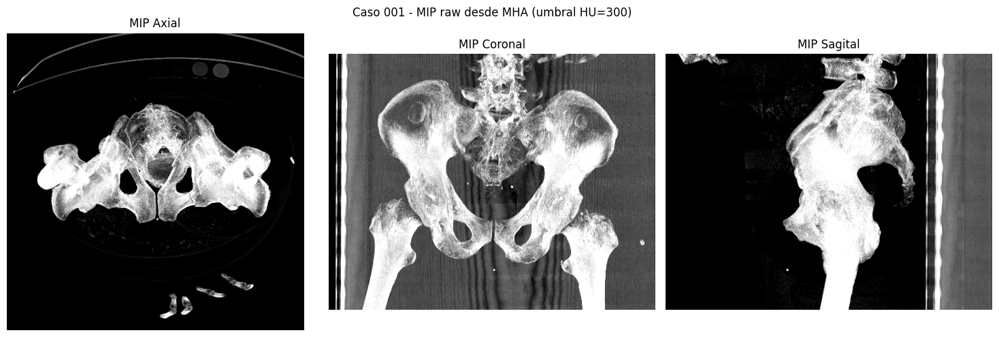

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# El volumen cargado con SimpleITK usa orden (z, y, x)
mip_axial = compute_mip(volume, hu_threshold=300, axis=0)
mip_coronal = compute_mip(volume, hu_threshold=300, axis=1)
mip_sagital = compute_mip(volume, hu_threshold=300, axis=2)

vmax_hueso = 1500

axes[0].imshow(mip_axial, cmap="gray", origin="lower", vmin=300, vmax=vmax_hueso)
axes[0].set_title("MIP Axial")
axes[0].axis("off")

axes[1].imshow(mip_coronal, cmap="gray", origin="lower", vmin=300, vmax=vmax_hueso)
axes[1].set_title("MIP Coronal")
axes[1].axis("off")

axes[2].imshow(mip_sagital, cmap="gray", origin="lower", vmin=300, vmax=vmax_hueso)
axes[2].set_title("MIP Sagital")
axes[2].axis("off")

plt.suptitle(f"Caso {case_id} - MIP raw desde MHA (umbral HU=300)")
plt.tight_layout()
plt.show()

### 2.3 Malla 3D interactiva

Se reconstruyen las superficies del sacro y los dos coxales mediante marching cubes. La malla permite rotar, desplazar y acercar el volumen, evitando la nube de puntos ruidosa del prototipo inicial. El HTML es una evidencia generada por este notebook.

In [5]:
import plotly.graph_objects as go
from skimage import measure

REGIONES_MALLA = {
    "sacro": {"labels": range(1, 11), "color": "#D9A62E"},
    "coxal_izquierdo": {"labels": range(11, 21), "color": "#2B8CBE"},
    "coxal_derecho": {"labels": range(21, 31), "color": "#E34A33"},
}


def crop_to_nonzero(mask, margin=8):
    coordinates = np.argwhere(mask)
    if len(coordinates) == 0:
        return None
    lower = np.maximum(coordinates.min(axis=0) - margin, 0)
    upper = np.minimum(coordinates.max(axis=0) + margin + 1, mask.shape)
    z0, y0, x0 = lower
    z1, y1, x1 = upper
    return mask[z0:z1, y0:y1, x0:x1], lower


def mesh_from_mask(mask, spacing_xyz, origin_zyx, stride=2):
    sampled = mask[::stride, ::stride, ::stride]
    spacing_zyx = (
        spacing_xyz[2] * stride,
        spacing_xyz[1] * stride,
        spacing_xyz[0] * stride,
    )
    vertices, faces, _, _ = measure.marching_cubes(
        sampled.astype(np.uint8), level=0.5, spacing=spacing_zyx
    )
    z = vertices[:, 0] + origin_zyx[0] * spacing_xyz[2]
    y = vertices[:, 1] + origin_zyx[1] * spacing_xyz[1]
    x = vertices[:, 2] + origin_zyx[2] * spacing_xyz[0]
    return x, y, z, faces


label_image = sitk.ReadImage(str(LABELS_DIR / "001.mha"))
label_volume = sitk.GetArrayFromImage(label_image)
spacing_xyz = label_image.GetSpacing()
mesh_traces = []

for region_name, config in REGIONES_MALLA.items():
    cropped = crop_to_nonzero(np.isin(label_volume, list(config["labels"])))
    if cropped is None:
        continue
    cropped_mask, origin_zyx = cropped
    x, y, z, faces = mesh_from_mask(cropped_mask, spacing_xyz, origin_zyx)
    mesh_traces.append(
        go.Mesh3d(
            x=x, y=y, z=z,
            i=faces[:, 2], j=faces[:, 1], k=faces[:, 0],
            color=config["color"], opacity=0.92,
            flatshading=False, name=region_name.replace("_", " "),
            lighting={"ambient": 0.42, "diffuse": 0.82, "roughness": 0.5},
        )
    )

mesh_figure = go.Figure(mesh_traces)
mesh_figure.update_layout(
    title="Caso 001 - malla 3D de sacro y coxales",
    scene={
        "xaxis_title": "x mm", "yaxis_title": "y mm", "zaxis_title": "z mm",
        "aspectmode": "data", "camera": {"eye": {"x": 1.45, "y": 1.4, "z": 0.85}},
    },
    legend={"orientation": "h", "y": 0.02},
    margin={"l": 0, "r": 0, "t": 50, "b": 0},
    dragmode="orbit",
)
HTML_DIR.mkdir(parents=True, exist_ok=True)
mesh_output = HTML_DIR / "visualizador_mesh_caso_001.html"
mesh_figure.write_html(mesh_output, include_plotlyjs=True)
print("Visualizador guardado en:", to_repo_relative(mesh_output))
mesh_figure

Visualizador guardado en: evidencias/visualizador_mesh_caso_001.html


ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'color': '#D9A62E',
              'flatshading': False,
              'i': {'bdata': ('AAAAAAIAAAAAAAAAAwAAAAUAAAAFAA' ... 'cAANFnAADSZwAA2GcAAOpnAADUZwAA'),
                    'dtype': 'i4'},
              'j': {'bdata': ('AQAAAAMAAAAEAAAABAAAAAYAAAAIAA' ... 'cAAOhnAADWZwAA6WcAAOlnAADqZwAA'),
                    'dtype': 'i4'},
              'k': {'bdata': ('AgAAAAAAAAABAAAAAAAAAAcAAAAJAA' ... 'cAANNnAADpZwAA1mcAANhnAADYZwAA'),
                    'dtype': 'i4'},
              'lighting': {'ambient': 0.42, 'diffuse': 0.82, 'roughness': 0.5},
              'name': 'sacro',
              'opacity': 0.92,
              'type': 'mesh3d',
              'x': {'bdata': ('AAAAAAAAaUAAAAAAAOdoQAAAAAAAAG' ... 'AAPmdAAAAAAADaZkAAAAAAAAxnQA=='),
                    'dtype': 'f8'},
              'y': {'bdata': ('AAAAAICgcUAAAAAAgKBxQAAAAAAAlH' ... 'AAX25AAAAAAACRbkAAAAAAAJFuQA=='),
                    'dtype': 'f8'},
              'z': {'bdata': ('AABAbmZmX0AAAIChmZlfQAAAgKGZmV' ... '2ZWXBAAACwnZlZcEAAALCdmVlwQA=='),
                    'dtype': 'f8'}},
             {'color': '#2B8CBE',
              'flatshading': False,
              'i': {'bdata': ('AAAAAAAAAAACAAAAAwAAAAYAAAAHAA' ... '0AACadAACVnQAAKJ0AAJadAAAcnQAA'),
                    'dtype': 'i4'},
              'j': {'bdata': ('AQAAAAMAAAADAAAABQAAAAEAAAABAA' ... '0AAJSdAACUnQAAlZ0AAJWdAACWnQAA'),
                    'dtype': 'i4'},
              'k': {'bdata': ('AgAAAAQAAAAAAAAABAAAAAAAAAAGAA' ... '0AACSdAAAmnQAAJp0AACidAAAonQAA'),
                    'dtype': 'i4'},
              'lighting': {'ambient': 0.42, 'diffuse': 0.82, 'roughness': 0.5},
              'name': 'coxal izquierdo',
              'opacity': 0.92,
              'type': 'mesh3d',
              'x': {'bdata': ('AAAAAAD7bUAAAAAAAOJtQAAAAAAA+2' ... 'CABHJAAAAAAIAdckAAAAAAgDZyQA=='),
                    'dtype': 'f8'},
              'y': {'bdata': ('AAAAAADPbEAAAAAAAM9sQAAAAAAAtm' ... 'AAw25AAAAAAADDbkAAAAAAAMNuQA=='),
                    'dtype': 'f8'},
              'z': {'bdata': ('AAAABwAATEAAAIBtZmZMQAAAgG1mZk' ... 'czM3FAAACANzMzcUAAAIA3MzNxQA=='),
                    'dtype': 'f8'}},
             {'color': '#E34A33',
              'flatshading': False,
              'i': {'bdata': ('AAAAAAAAAAACAAAAAwAAAAYAAAAHAA' ... 'B5ngAAwZ4AAG2eAAB0ngAAd54AAA=='),
                    'dtype': 'i4'},
              'j': {'bdata': ('AQAAAAMAAAADAAAABQAAAAEAAAABAA' ... 'DAngAAwJ4AAMGeAACBngAAwp4AAA=='),
                    'dtype': 'i4'},
              'k': {'bdata': ('AgAAAAQAAAAAAAAABAAAAAAAAAAGAA' ... 'B2ngAAeZ4AAHmeAADCngAAgZ4AAA=='),
                    'dtype': 'i4'},
              'lighting': {'ambient': 0.42, 'diffuse': 0.82, 'roughness': 0.5},
              'name': 'coxal derecho',
              'opacity': 0.92,
              'type': 'mesh3d',
              'x': {'bdata': ('AAAAAACCZEAAAAAAAGlkQAAAAAAAgm' ... 'AAQF9AAAAAAACkX0AAAAAAANxeQA=='),
                    'dtype': 'f8'},
              'y': {'bdata': ('AAAAAACEbEAAAAAAAIRsQAAAAAAAa2' ... 'AAhGxAAAAAAACEbEAAAAAAALZsQA=='),
                    'dtype': 'f8'},
              'z': {'bdata': ('AAAAOzMzT0AAAIChmZlPQAAAgKGZmU' ... '6ZGXJAAAAgnpkZckAAACCemRlyQA=='),
                    'dtype': 'f8'}}],
    'layout': {'dragmode': 'orbit',
               'legend': {'orientation': 'h', 'y': 0.02},
               'margin': {'b': 0, 'l': 0, 'r': 0, 't': 50},
               'scene': {'aspectmode': 'data',
                         'camera': {'eye': {'x': 1.45, 'y': 1.4, 'z': 0.85}},
                         'xaxis': {'title': {'text': 'x mm'}},
                         'yaxis': {'title': {'text': 'y mm'}},
                         'zaxis': {'title': {'text': 'z mm'}}},
               'template': '...',
               'title': {'text': 'Caso 001 - malla 3D de sacro y coxales'}}
})